# 8-a

In [15]:

from bs4 import BeautifulSoup
import pandas as pd

# Read the saved HTML file
with open(r"C:\Users\DELL\Downloads\DS_Program8_Complete_Data_Files\DS_Program8_Complete_Data_Files\reviews.html", "r", encoding="utf-8") as file:
    html_content = file.read()

soup = BeautifulSoup(html_content, "html.parser")

# Find review sections
review_blocks = soup.select(".review")
records = []

for block in review_blocks:
    review_element = block.select_one(".review-text")
    rating_element = block.select_one(".rating")
    title_element = block.select_one(".review-title")

    review = (
        review_element.get_text(" ", strip=True)
        if review_element else ""
    )
    rating = (
        rating_element.get_text(" ", strip=True)
        if rating_element else ""
    )
    title = (
        title_element.get_text(" ", strip=True)
        if title_element else ""
    )

    if review:
        records.append({
            "title": title,
            "review": review,
            "rating": rating
        })

df = pd.DataFrame(records)
df.to_csv("product_reviews.csv", index=False, encoding="utf-8-sig")

print(df.head())
print("Total reviews extracted:", len(df))
print("Saved to product_reviews.csv")



             title                                             review  \
0    Great product  Excellent quality and very useful product. Del...   
1     Poor quality  Poor quality and the product stopped working a...   
2     Worth buying  Good performance and excellent value for money...   
3   Bad experience  Very bad product. I am disappointed and custom...   
4  Excellent value  Great product with amazing features and a clea...   

       rating  
0  5 out of 5  
1  2 out of 5  
2  4 out of 5  
3  1 out of 5  
4  5 out of 5  
Total reviews extracted: 20
Saved to product_reviews.csv


# 8-b

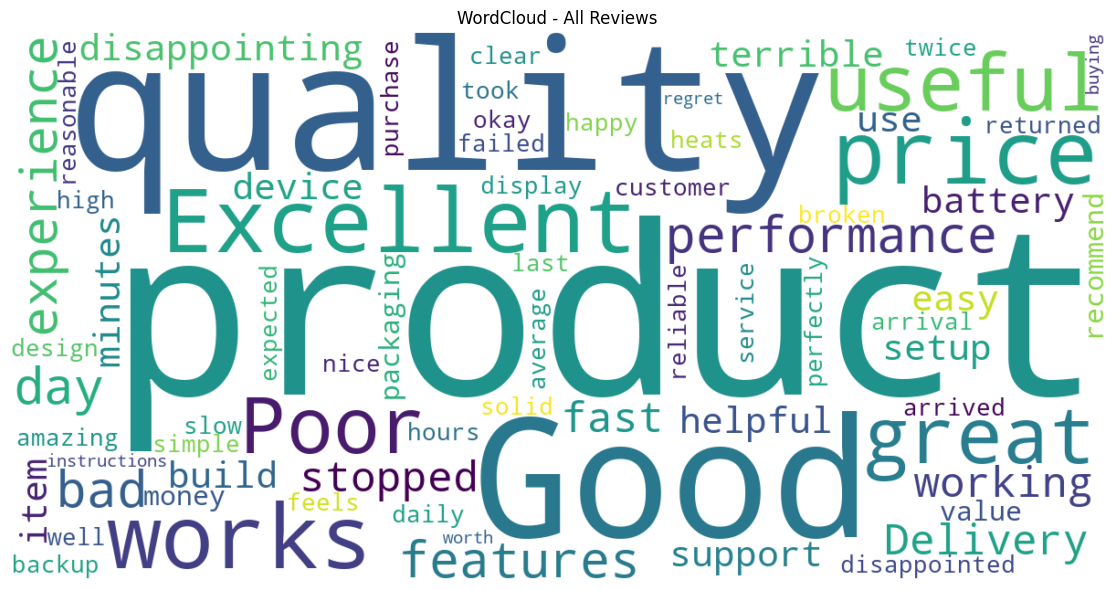

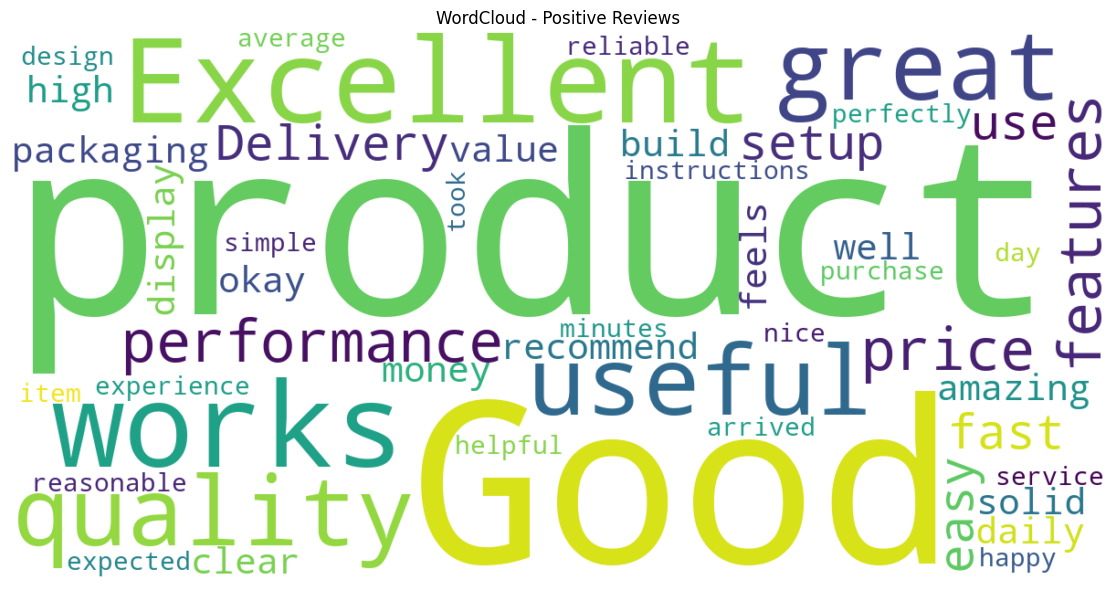

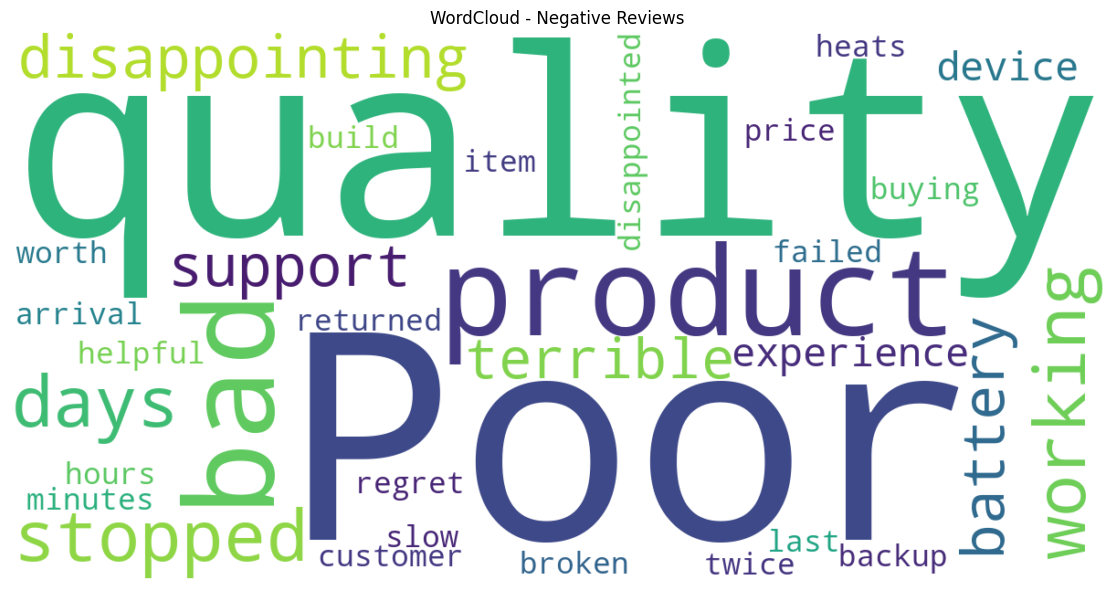

sentiment
Positive    12
Negative     8
Name: count, dtype: int64
WordCloud images saved successfully.


In [16]:

import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

df = pd.read_csv(r"C:\Users\DELL\Downloads\DS_Program8_Complete_Data_Files\DS_Program8_Complete_Data_Files\product_reviews.csv")
df["review"] = df["review"].fillna("").astype(str)

analyzer = SentimentIntensityAnalyzer()

def classify_sentiment(text):
    score = analyzer.polarity_scores(text)["compound"]

    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    return "Neutral"

df["sentiment"] = df["review"].apply(classify_sentiment)

def generate_wordcloud(text, title, filename):
    if not text.strip():
        print("No text available for:", title)
        return

    cloud = WordCloud(
        width=1200,
        height=600,
        background_color="white",
        max_words=150,
        collocations=False
    ).generate(text)

    plt.figure(figsize=(12, 6))
    plt.imshow(cloud, interpolation="bilinear")
    plt.axis("off")
    plt.title(title)
    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()

# All reviews
all_text = " ".join(df["review"])
generate_wordcloud(
    all_text, "WordCloud - All Reviews", "wordcloud_all.png"
)

# Positive reviews
positive_text = " ".join(
    df.loc[df["sentiment"] == "Positive", "review"]
)
generate_wordcloud(
    positive_text, "WordCloud - Positive Reviews",
    "wordcloud_positive.png"
)

# Negative reviews
negative_text = " ".join(
    df.loc[df["sentiment"] == "Negative", "review"]
)
generate_wordcloud(
    negative_text, "WordCloud - Negative Reviews",
    "wordcloud_negative.png"
)

df.to_csv("product_reviews_analyzed.csv", index=False)
print(df["sentiment"].value_counts())
print("WordCloud images saved successfully.")


# 8-c

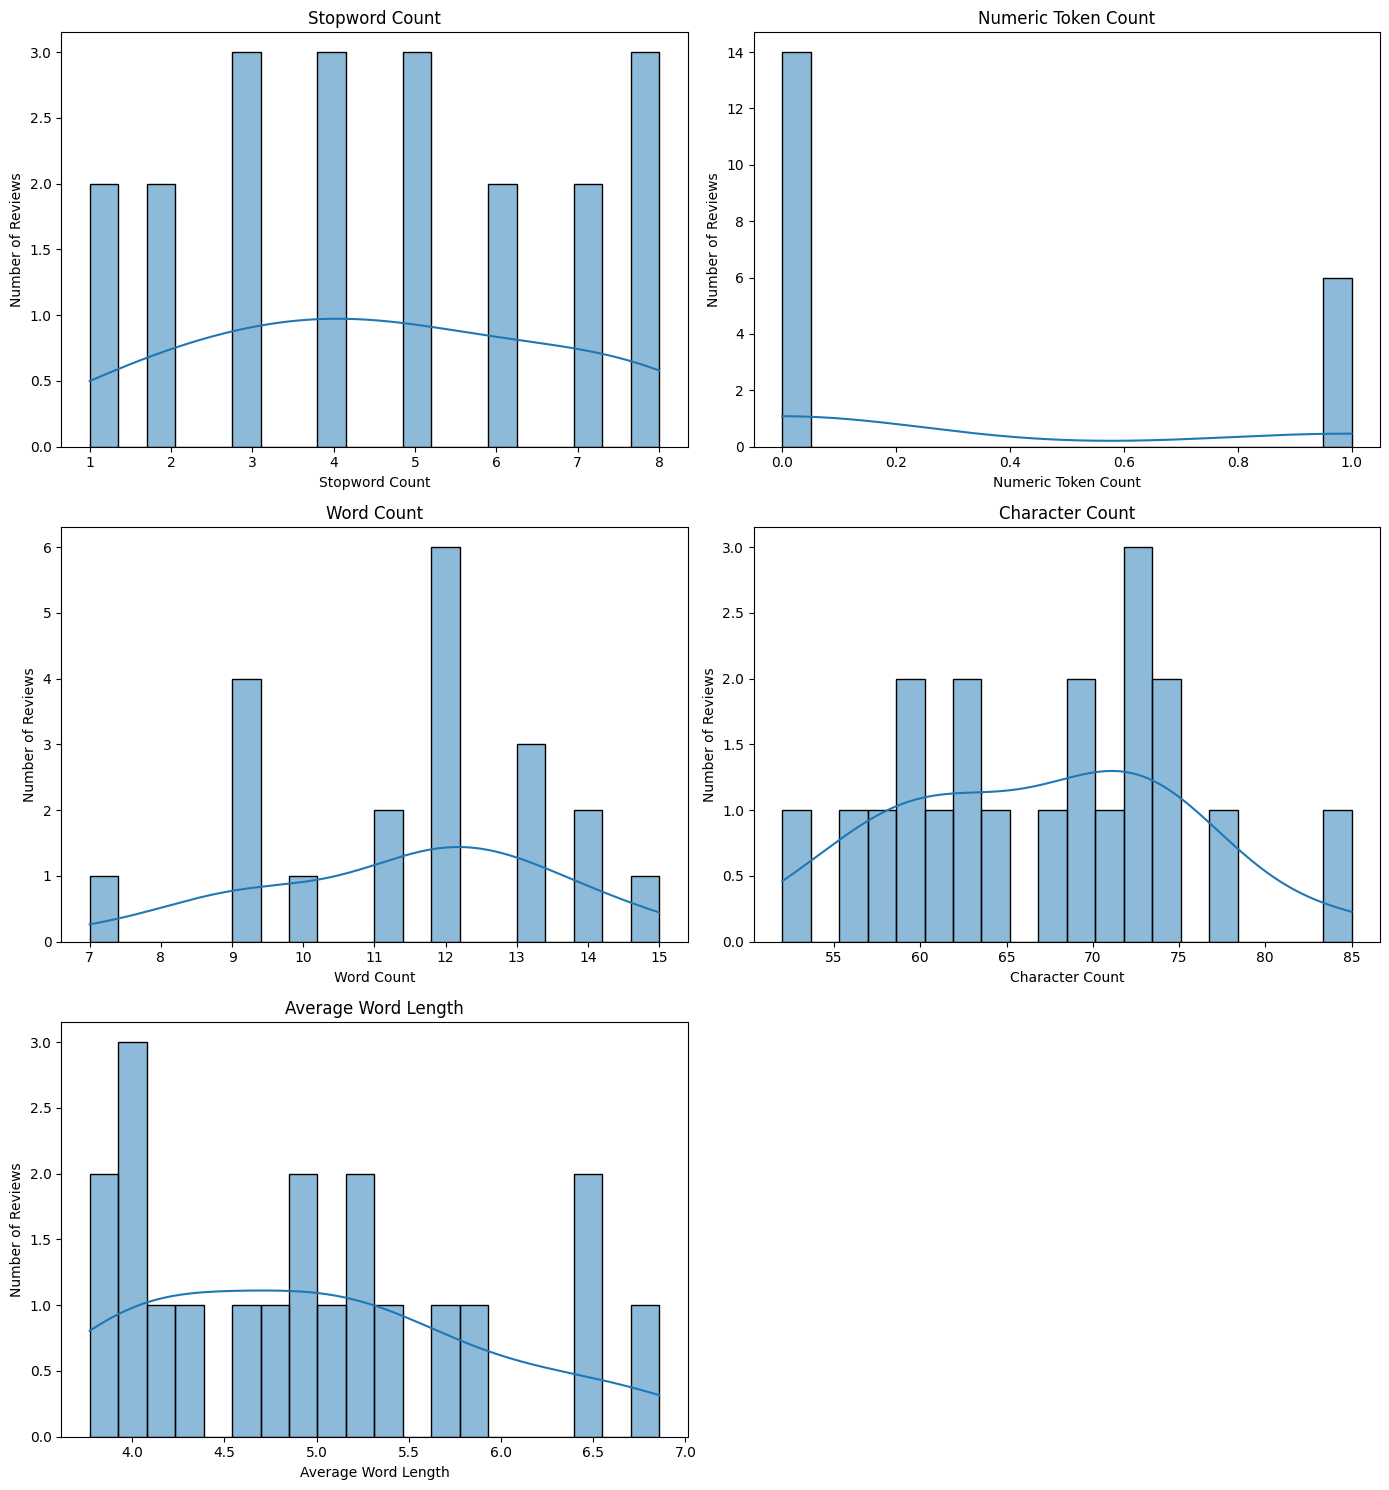

Top 10 stopwords:
[('and', 19), ('the', 16), ('is', 10), ('it', 7), ('was', 5), ('i', 5), ('very', 4), ('for', 4), ('after', 3), ('not', 3)]

Descriptive statistics:
       stopword_count  numeric_count  word_count  character_count  \
count       20.000000      20.000000   20.000000         20.00000   
mean         4.600000       0.300000   11.450000         67.10000   
std          2.280351       0.470162    2.064104          8.44736   
min          1.000000       0.000000    7.000000         52.00000   
25%          3.000000       0.000000    9.750000         60.50000   
50%          4.500000       0.000000   12.000000         68.50000   
75%          6.250000       1.000000   13.000000         73.00000   
max          8.000000       1.000000   15.000000         85.00000   

       average_word_length  
count            20.000000  
mean              4.975126  
std               0.922489  
min               3.769231  
25%               4.080357  
50%               4.954545  
75%      

In [17]:

import re
import pandas as pd
import nltk
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.corpus import stopwords
from collections import Counter

nltk.download("stopwords", quiet=True)

df = pd.read_csv("product_reviews.csv")
df["review"] = df["review"].fillna("").astype(str)

stop_words = set(stopwords.words("english"))

def analyze_review(text):
    tokens = re.findall(r"\b[\w']+\b", text.lower())
    words = re.findall(r"\b[A-Za-z]+\b", text)
    numeric_tokens = re.findall(r"\b\d+(?:\.\d+)?\b", text)

    stopword_tokens = [
        token for token in tokens if token in stop_words
    ]

    return pd.Series({
        "word_count": len(tokens),
        "character_count": len(text),
        "numeric_count": len(numeric_tokens),
        "stopword_count": len(stopword_tokens),
        "average_word_length": (
            sum(len(word) for word in words) / len(words)
            if words else 0
        )
    })

statistics = df["review"].apply(analyze_review)
df = pd.concat([df, statistics], axis=1)

df.to_csv("review_statistics.csv", index=False)

columns = [
    ("stopword_count", "Stopword Count"),
    ("numeric_count", "Numeric Token Count"),
    ("word_count", "Word Count"),
    ("character_count", "Character Count"),
    ("average_word_length", "Average Word Length")
]

fig, axes = plt.subplots(3, 2, figsize=(14, 15))
axes = axes.flatten()

for i, (column, title) in enumerate(columns):
    sns.histplot(
        data=df, x=column, kde=True,
        ax=axes[i], bins=20
    )
    axes[i].set_title(title)
    axes[i].set_xlabel(title)
    axes[i].set_ylabel("Number of Reviews")

axes[-1].axis("off")
plt.tight_layout()
plt.savefig("review_statistics_distributions.png", dpi=300)
plt.show()

all_tokens = re.findall(
    r"\b[\w']+\b", " ".join(df["review"]).lower()
)
stopword_frequency = Counter(
    token for token in all_tokens if token in stop_words
)

print("Top 10 stopwords:")
print(stopword_frequency.most_common(10))

print("\nDescriptive statistics:")
print(df[[
    "stopword_count",
    "numeric_count",
    "word_count",
    "character_count",
    "average_word_length"
]].describe())


# 8-d

In [19]:

import pandas as pd
import nltk
from nltk.sentiment.vader import (
    SentimentIntensityAnalyzer as NLTKVADER
)
from vaderSentiment.vaderSentiment import (
    SentimentIntensityAnalyzer as StandaloneVADER
)

nltk.download("vader_lexicon", quiet=True)

df = pd.read_csv("product_reviews.csv")
df["review"] = df["review"].fillna("").astype(str)

nltk_analyzer = NLTKVADER()
vader_analyzer = StandaloneVADER()

def classify(score):
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    return "Neutral"

# NLTK VADER scores
nltk_scores = df["review"].apply(
    nltk_analyzer.polarity_scores
)

df["nltk_positive"] = nltk_scores.apply(lambda x: x["pos"])
df["nltk_negative"] = nltk_scores.apply(lambda x: x["neg"])
df["nltk_neutral"] = nltk_scores.apply(lambda x: x["neu"])
df["nltk_compound"] = nltk_scores.apply(lambda x: x["compound"])

# Standalone VADER scores
vader_scores = df["review"].apply(
    vader_analyzer.polarity_scores
)

df["vader_positive"] = vader_scores.apply(lambda x: x["pos"])
df["vader_negative"] = vader_scores.apply(lambda x: x["neg"])
df["vader_neutral"] = vader_scores.apply(lambda x: x["neu"])
df["vader_compound"] = vader_scores.apply(lambda x: x["compound"])

df["nltk_sentiment"] = df["nltk_compound"].apply(classify)
df["vader_sentiment"] = df["vader_compound"].apply(classify)

print(df[[
    "review",
    "nltk_compound",
    "nltk_sentiment",
    "vader_compound",
    "vader_sentiment"
]].head(10).to_string(index=False))

print("\nNLTK sentiment distribution:")
print(df["nltk_sentiment"].value_counts())

print("\nStandalone VADER sentiment distribution:")
print(df["vader_sentiment"].value_counts())

df.to_csv("sentiment_analysis_results.csv", index=False)
print("\nResults saved to sentiment_analysis_results.csv")


                                                                               review  nltk_compound nltk_sentiment  vader_compound vader_sentiment
Excellent quality and very useful product. Delivery was fast and packaging was great.         0.8999       Positive          0.8999        Positive
       Poor quality and the product stopped working after 2 days. Very disappointing.        -0.8173       Negative         -0.8173        Negative
                Good performance and excellent value for money. I would recommend it.         0.8885       Positive          0.8885        Positive
            Very bad product. I am disappointed and customer support was not helpful.        -0.7597       Negative         -0.7597        Negative
                             Great product with amazing features and a clear display.         0.8885       Positive          0.8885        Positive
           The product is slow and the battery is terrible. It does not last 3 hours.        -0.4767       Negat

# 8-e

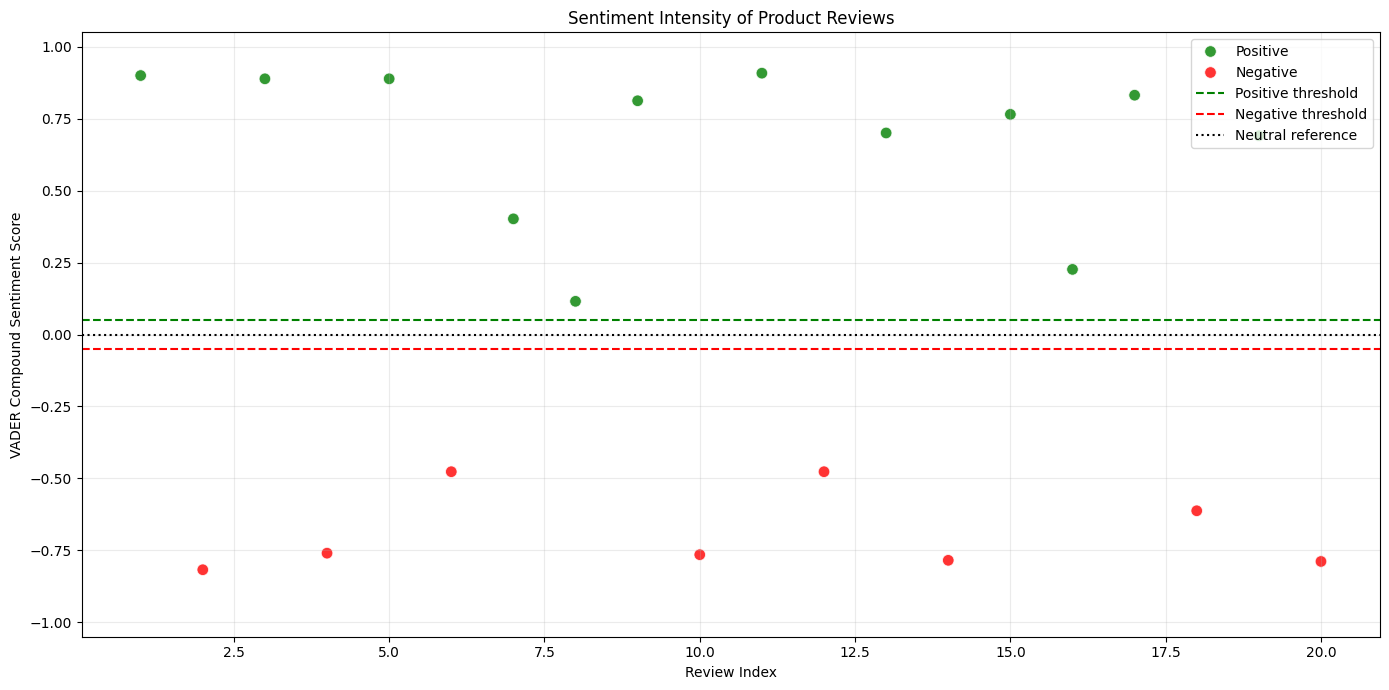

Scatter intensity plot saved successfully.


In [20]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("sentiment_analysis_results.csv")

df["vader_compound"] = pd.to_numeric(
    df["vader_compound"], errors="coerce"
)

df = df.dropna(
    subset=["vader_compound"]
).reset_index(drop=True)

df["review_index"] = range(1, len(df) + 1)

palette = {
    "Positive": "green",
    "Negative": "red",
    "Neutral": "gray"
}

plt.figure(figsize=(14, 7))

sns.scatterplot(
    data=df,
    x="review_index",
    y="vader_compound",
    hue="vader_sentiment",
    palette=palette,
    s=70,
    alpha=0.8
)

plt.axhline(
    y=0.05, color="green", linestyle="--",
    label="Positive threshold"
)
plt.axhline(
    y=-0.05, color="red", linestyle="--",
    label="Negative threshold"
)
plt.axhline(
    y=0, color="black", linestyle=":",
    label="Neutral reference"
)

plt.ylim(-1.05, 1.05)
plt.xlabel("Review Index")
plt.ylabel("VADER Compound Sentiment Score")
plt.title("Sentiment Intensity of Product Reviews")
plt.legend(loc="best")
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig("sentiment_intensity_scatter.png", dpi=300)
plt.show()

print("Scatter intensity plot saved successfully.")
